# 3. Modelagem Econométrica — Probabilidade de Trabalho Remoto e Interação do Ensino Superior

Neste notebook estimamos modelos **Logit ponderados pelos pesos amostrais (`V1032`)** sobre o **universo completo de trabalhadores ocupados não afastados no mercado de trabalho** (`amostra_modelo == True`), utilizando erro-padrão robusto à heterocedasticidade (`HC1`).

### Estratégia Econométrica
Estimamos dois modelos para **maio/2020** (pico do isolamento social e do trabalho remoto) e replicamos para **novembro/2020** (estabilidade temporal após reabertura):

$$P(Y_i = 1 \mid X_i) = \Lambda(X_i \beta) = \frac{1}{1 + e^{-X_i \beta}}$$

1. **Modelo 1 — Efeitos Principais**: escolaridade em 8 níveis (referência: *Médio completo*) + controles de gênero, raça, faixa etária, macrorregião, formalidade, iniciativa e setor de atividade. Reportamos **Odds Ratios (OR)** e **Efeitos Marginais Médios (AME em pontos percentuais)** com intervalos de confiança de 95% via método delta.
2. **Modelo 2 — Interações do Ensino Superior**: substitui os 8 níveis por uma indicadora `ensino_superior` (1 = Superior completo ou pós) interagida com gênero, raça, iniciativa, formalidade e setor. Como coeficientes de interação em modelos não lineares não representam diretamente a mudança de probabilidade (Ai & Norton, 2003), avaliamos **probabilidades preditas médias ponderadas** e o **ganho marginal do ensino superior em p.p.** por subgrupo.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import PALETTE, PROCESSED_DATA_PATH
from src.data_processing import load_analytic_dataset
from src.modeling import (
    REF_CATEGORIES,
    build_design_matrix_interaction,
    build_design_matrix_main,
    compute_calibration_bins,
    compute_diagnostics,
    compute_subgroup_predictions,
    compute_vif,
    compute_weighted_roc,
    fit_weighted_logit,
    prepare_model_sample,
    summarize_logit,
)
from src.visualization import (
    add_title_and_source,
    format_ptbr_number,
    save_figure,
    set_portfolio_style,
    style_percent_axis,
)

set_portfolio_style()
df = load_analytic_dataset(PROCESSED_DATA_PATH)

df_mai = prepare_model_sample(df, mes=5)
df_nov = prepare_model_sample(df, mes=11)

print(f"Amostra Modelo — Maio/2020:     {len(df_mai):,} obs (Taxa remota ponderada: {np.average(df_mai['trabalho_remoto'], weights=df_mai['peso'])*100:.2f}%)")
print(f"Amostra Modelo — Novembro/2020: {len(df_nov):,} obs (Taxa remota ponderada: {np.average(df_nov['trabalho_remoto'], weights=df_nov['peso'])*100:.2f}%)")
print("\nCategorias de referência:", REF_CATEGORIES)


Amostra Modelo — Maio/2020:     106,686 obs (Taxa remota ponderada: 13.31%)
Amostra Modelo — Novembro/2020: 137,621 obs (Taxa remota ponderada: 9.14%)

Categorias de referência: {'genero': 'Homem', 'raca': 'Branca e Amarela', 'faixa_etaria_modelo': '35-44', 'regiao': 'Sudeste', 'formalidade': 'Informal', 'iniciativa': 'Privado', 'setor': 'Serviços', 'escolaridade': 'Médio completo'}


## 3.1 Modelo 1 — Efeitos Diretos da Escolaridade e Controles (Maio/2020)

Controlando simultaneamente todas as características individuais, regionais e ocupacionais:
- **Escolaridade é o determinante dominante**: comparando com quem possui ensino médio completo, ter **Superior completo** eleva a probabilidade média de trabalho remoto em **+21,7 p.p.** (OR = 7,34; IC 95% [6,76; 7,97]) e **Pós-graduação/Mestrado/Doutorado** eleva em **+35,5 p.p.** (OR = 14,65; IC 95% [13,19; 16,28]). Mesmo o **Superior incompleto** amplia em **+12,9 p.p.** (OR = 4,24).
- **Demografia e Região**: mulheres mantêm efeito positivo moderado (**+1,3 p.p.**, OR = 1,16), enquanto pretos, pardos e indígenas apresentam redução de **−2,6 p.p.** (OR = 0,74). Trabalhadores com 65+ anos (+6,1 p.p.) e residentes no Sudeste também têm maior propensão ao home office.
- **Setor e Iniciativa**: Agricultura (**−11,3 p.p.**, OR = 0,18), Comércio (**−6,9 p.p.**, OR = 0,43) e Indústria (**−5,9 p.p.**, OR = 0,50) ficam bem abaixo de Serviços.
- **Colinearidade (VIF)**: todos os preditores exibem VIF muito abaixo do limiar crítico (**máximo de 2,05** em `Iniciativa: Público` e **1,63** em `Setor: Administração Pública`), confirmando separação limpa entre vínculo público na administração direta e demais serviços públicos (educação e saúde).


In [2]:
X1_mai, y1_mai, w1_mai = build_design_matrix_main(df_mai)
res1_mai = fit_weighted_logit(y1_mai, X1_mai, w1_mai)
summary1_mai = summarize_logit(res1_mai, X1_mai, w1_mai, include_ame=True)

cols_show1 = ["label", "coef", "se_hc1", "p_valor", "odds_ratio", "or_ic_inf", "or_ic_sup", "ame_pp", "ame_ic_inf", "ame_ic_sup"]
display(summary1_mai[cols_show1].round({"coef": 3, "se_hc1": 3, "p_valor": 4, "odds_ratio": 3, "or_ic_inf": 3, "or_ic_sup": 3, "ame_pp": 2, "ame_ic_inf": 2, "ame_ic_sup": 2}))

vif_mai = compute_vif(X1_mai)
print("\nTop 8 maiores VIFs (checagem de colinearidade):")
display(vif_mai.head(8).round(2))


,label,coef,se_hc1,p_valor,odds_ratio,or_ic_inf,or_ic_sup,ame_pp,ame_ic_inf,ame_ic_sup
0,Intercepto,-2.192,0.070,0.0000,0.112,0.097,0.128,NaN,NaN,NaN
1,Escolaridade: Sem instrução,-2.142,0.446,0.0000,0.117,0.049,0.281,-4.62,-5.28,-3.95
2,Escolaridade: Fundamental incompleto,-1.829,0.131,0.0000,0.161,0.124,0.207,-4.38,-4.78,-3.97
3,Escolaridade: Fundamental completo,-1.162,0.140,0.0000,0.313,0.238,0.411,-3.54,-4.10,-2.98
4,Escolaridade: Médio incompleto,-0.811,0.109,0.0000,0.444,0.359,0.550,-2.83,-3.42,-2.25
5,Escolaridade: Superior incompleto,1.444,0.054,0.0000,4.236,3.810,4.710,12.91,11.73,14.09
6,Escolaridade: Superior completo,1.993,0.042,0.0000,7.341,6.758,7.974,21.69,20.79,22.59
7,Escolaridade: Pós-graduação/Mestrado/Doutorado,2.685,0.054,0.0000,14.652,13.190,16.275,35.46,33.67,37.25
8,Gênero: Mulher (ref. Homem),0.148,0.031,0.0000,1.160,1.092,1.232,1.28,0.75,1.80
9,"Raça: Pretos, Pardos e Indígenas",-0.304,0.033,0.0000,0.738,0.692,0.787,-2.60,-3.14,-2.05



Top 8 maiores VIFs (checagem de colinearidade):


,variavel,label,vif
0,iniciativa__Público,Iniciativa: Público (ref. Privado),2.05
1,setor__Setor Público,Setor: Administração Pública,1.63
2,escolaridade__Fundamental incompleto,Escolaridade: Fundamental incompleto,1.59
3,iniciativa__Outros,Iniciativa: Outros (Conta própria/Empreg./Dom.),1.58
4,setor__Agricultura,Setor: Agricultura,1.53
5,formalidade__Formal,Vínculo: Formal (ref. Informal),1.51
6,faixa_etaria_modelo__25-34,Idade: 25–34 anos,1.46
7,faixa_etaria_modelo__45-54,Idade: 45–54 anos,1.45


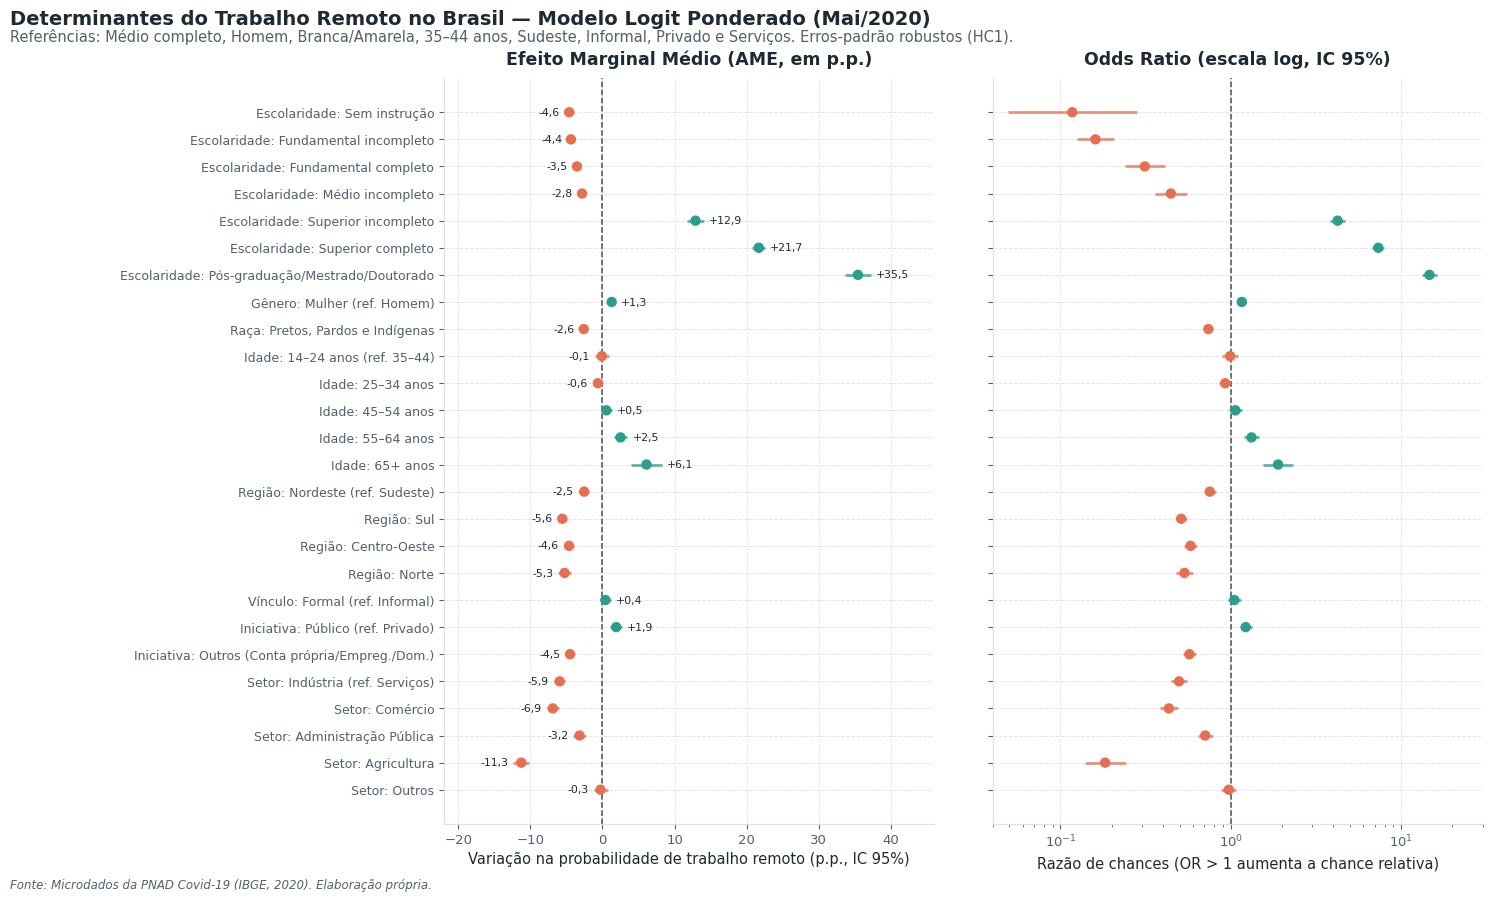

In [3]:
# Figura 07: Forest plot duplo (AME em p.p. e Odds Ratio em escala log) — Modelo 1 Mai/2020
plot1_df = summary1_mai[summary1_mai["variavel"] != "const"].copy()
# Ordem reversa da tabela para leitura de cima para baixo
plot1_df = plot1_df.iloc[::-1].reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 9.2), sharey=True)
fig.subplots_adjust(top=0.89, bottom=0.08, left=0.30, right=0.97, wspace=0.12)

y_pos = np.arange(len(plot1_df))
colors_ame = [
    PALETTE["teal"] if v >= 0 else PALETTE["coral"]
    for v in plot1_df["ame_pp"]
]

# Painel esquerdo: AME (p.p.)
ax1.axvline(0.0, color=PALETTE["dark_text"], lw=1.1, ls="--", alpha=0.8)
ax1.hlines(y_pos, plot1_df["ame_ic_inf"], plot1_df["ame_ic_sup"], color=colors_ame, lw=2.0, alpha=0.75)
ax1.scatter(plot1_df["ame_pp"], y_pos, color=colors_ame, s=42, zorder=3)
for yi, row in plot1_df.iterrows():
    ha = "left" if row["ame_pp"] >= 0 else "right"
    x_txt = row["ame_ic_sup"] + 0.7 if row["ame_pp"] >= 0 else row["ame_ic_inf"] - 0.7
    sinal = "+" if row["ame_pp"] >= 0 else ""
    ax1.text(x_txt, yi, f"{sinal}{format_ptbr_number(row['ame_pp'], 1)}", va="center", ha=ha, fontsize=7.8, color=PALETTE["dark_text"])

ax1.set_yticks(y_pos)
ax1.set_yticklabels(plot1_df["label"], fontsize=9)
ax1.set_xlim(-22, 46)
ax1.set_title("Efeito Marginal Médio (AME, em p.p.)", pad=10)
ax1.set_xlabel("Variação na probabilidade de trabalho remoto (p.p., IC 95%)")

# Painel direito: Odds Ratio (escala log)
ax2.axvline(1.0, color=PALETTE["dark_text"], lw=1.1, ls="--", alpha=0.8)
ax2.hlines(y_pos, plot1_df["or_ic_inf"], plot1_df["or_ic_sup"], color=colors_ame, lw=2.0, alpha=0.75)
ax2.scatter(plot1_df["odds_ratio"], y_pos, color=colors_ame, s=42, zorder=3)
ax2.set_xscale("log")
ax2.set_xlim(0.04, 30)
ax2.set_title("Odds Ratio (escala log, IC 95%)", pad=10)
ax2.set_xlabel("Razão de chances (OR > 1 aumenta a chance relativa)")

add_title_and_source(
    fig,
    "Determinantes do Trabalho Remoto no Brasil — Modelo Logit Ponderado (Mai/2020)",
    "Referências: Médio completo, Homem, Branca/Amarela, 35–44 anos, Sudeste, Informal, Privado e Serviços. Erros-padrão robustos (HC1).",
    title_y=0.965,
    subtitle_y=0.93,
    source_y=0.01,
)
save_figure(fig, "07_logit_efeitos_marginais_or.png")
plt.show()


## 3.2 Modelo 2 — Interações do Ensino Superior (Maio/2020)

O segundo modelo investiga **como a presença de ensino superior interage com gênero, cor/raça, iniciativa, formalidade e setor**:

- **Desigualdade racial**: entre trabalhadores *sem* ensino superior, pretos, pardos e indígenas têm chances 41,6% menores (OR = 0,584); a interação positiva (`Superior × PPI`, OR = 1,254, p = 0,0002) atenua essa razão relativa de desigualdade (a razão de probabilidades cai de 1,64× sem superior para 1,22× com superior: **26,8%** vs. **32,6%**), embora o ganho em p.p. seja de **+22,4 p.p.** vs. **+25,5 p.p.** pela diferença na linha de base.
- **Setores de baixa incidência remota**: na **Agricultura** e na **Indústria**, o ensino superior multiplica as razões de chance em relação a quem não tem superior (`Superior × Agricultura` OR = 4,31, p < 0,001, elevando a probabilidade predita de **0,5%** para **14,1%**; `Superior × Indústria` OR = 1,48, p = 0,0003, elevando de **2,9%** para **25,7%**). No **Comércio** (`Superior × Comércio` OR = 0,55), o ganho existe (+11,9 p.p., chegando a 16,1%), porém é mais contido que em Serviços (+30,5 p.p.).
- **Gênero e Setor Público**: os coeficientes de interação negativos (`Superior × Mulher`, OR = 0,751; `Superior × Administração Pública`, OR = 0,595) indicam compressão da vantagem *relativa* (em *log-odds*) entre graduados; ainda assim, em **pontos percentuais**, mulheres com superior registram probabilidade predita superior à dos homens (**30,5%** vs. **29,1%**), e no vínculo **Formal** (`Superior × Formal` OR = 1,346, p = 0,0011) o ganho do diploma supera o do informal (**+25,2 p.p.** vs. **+20,2 p.p.**).


In [4]:
X2_mai, y2_mai, w2_mai = build_design_matrix_interaction(df_mai)
res2_mai = fit_weighted_logit(y2_mai, X2_mai, w2_mai)
summary2_mai = summarize_logit(res2_mai, include_ame=False)

foco_vars = ["ensino_superior"] + [
    c for c in X2_mai.columns
    if c.startswith("sup_x_") or c in (
        "genero__Mulher", "raca__Pretos, Pardos e Indígenas",
        "iniciativa__Público", "iniciativa__Outros", "formalidade__Formal",
        "setor__Indústria", "setor__Comércio", "setor__Setor Público", "setor__Agricultura", "setor__Outros"
    )
]
display(
    summary2_mai.set_index("variavel").loc[foco_vars, ["label", "coef", "se_hc1", "p_valor", "odds_ratio", "or_ic_inf", "or_ic_sup"]]
    .round({"coef": 3, "se_hc1": 3, "p_valor": 4, "odds_ratio": 3, "or_ic_inf": 3, "or_ic_sup": 3})
)

sub_mai = compute_subgroup_predictions(
    res2_mai,
    df_mai,
    build_design_matrix_interaction,
    w2_mai,
    dimensions=["genero", "raca", "iniciativa", "formalidade", "setor"],
)
print("\nProbabilidades preditas médias ponderadas (Sem vs. Com Ensino Superior) e ganho marginal (p.p.):")
display(sub_mai.round(2))


,label,coef,se_hc1,p_valor,odds_ratio,or_ic_inf,or_ic_sup
variavel,,,,,,,
ensino_superior,Ensino superior completo ou pós,1.891,0.111,0.0000,6.626,5.328,8.240
genero__Mulher,Gênero: Mulher (ref. Homem),0.358,0.052,0.0000,1.430,1.292,1.584
"raca__Pretos, Pardos e Indígenas","Raça: Pretos, Pardos e Indígenas",-0.538,0.049,0.0000,0.584,0.530,0.642
formalidade__Formal,Vínculo: Formal (ref. Informal),-0.037,0.066,0.5791,0.964,0.846,1.098
iniciativa__Público,Iniciativa: Público (ref. Privado),0.302,0.084,0.0003,1.353,1.147,1.596
iniciativa__Outros,Iniciativa: Outros (Conta própria/Empreg./Dom.),-0.663,0.068,0.0000,0.515,0.451,0.589
setor__Indústria,Setor: Indústria (ref. Serviços),-0.996,0.083,0.0000,0.369,0.314,0.435
setor__Comércio,Setor: Comércio,-0.615,0.079,0.0000,0.540,0.463,0.631
setor__Setor Público,Setor: Administração Pública,0.014,0.101,0.8897,1.014,0.833,1.235



Probabilidades preditas médias ponderadas (Sem vs. Com Ensino Superior) e ganho marginal (p.p.):


,dimensao,categoria,prob_sem_superior_pct,prob_sem_sup_se_pp,prob_com_superior_pct,prob_com_sup_se_pp,ganho_superior_pp,ganho_ic_inf_pp,ganho_ic_sup_pp,razao_chances_marginal
0,genero,Homem,4.90,0.16,29.13,0.57,24.23,23.07,25.39,5.95
1,genero,Mulher,6.79,0.22,30.47,0.57,23.68,22.48,24.89,4.49
2,raca,Branca e Amarela,7.14,0.22,32.65,0.54,25.51,24.37,26.65,4.58
3,raca,"Pretos, Pardos e Indígenas",4.36,0.14,26.79,0.62,22.43,21.19,23.67,6.15
4,iniciativa,Privado,6.43,0.21,32.42,0.68,25.99,24.58,27.41,5.05
5,iniciativa,Público,8.42,0.53,39.11,0.96,30.69,28.55,32.84,4.64
6,iniciativa,Outros,3.47,0.18,21.80,0.70,18.33,16.93,19.73,6.29
7,formalidade,Formal,5.72,0.15,30.93,0.50,25.21,24.20,26.23,5.41
8,formalidade,Informal,5.92,0.30,26.13,1.03,20.22,18.11,22.33,4.42
9,setor,Serviços,7.46,0.23,38.01,0.61,30.55,29.26,31.83,5.10


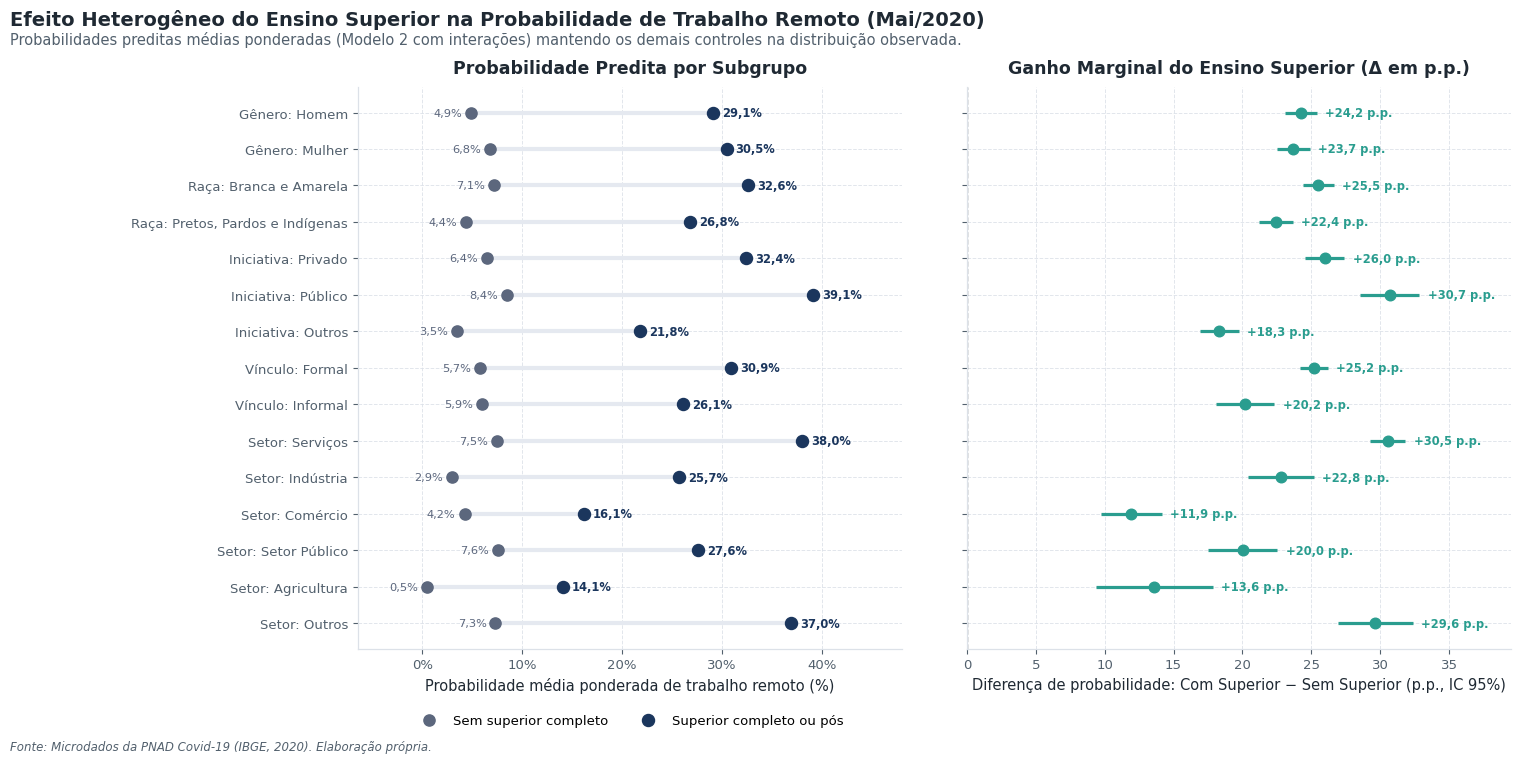

In [5]:
# Figura 08: Dumbbell de probabilidades preditas + Ganho marginal do Ensino Superior (p.p.)
sub_plot = sub_mai.copy()
dim_names = {
    "genero": "Gênero",
    "raca": "Raça",
    "iniciativa": "Iniciativa",
    "formalidade": "Vínculo",
    "setor": "Setor",
}
sub_plot["grupo_label"] = sub_plot["dimensao"].map(dim_names) + ": " + sub_plot["categoria"]
sub_plot = sub_plot.iloc[::-1].reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.8, 7.8), sharey=True)
fig.subplots_adjust(top=0.86, bottom=0.14, left=0.24, right=0.97, wspace=0.12)

y_pos = np.arange(len(sub_plot))

# Painel esquerdo: Probabilidade predita Sem vs Com Superior
ax1.hlines(y_pos, sub_plot["prob_sem_superior_pct"], sub_plot["prob_com_superior_pct"], color=PALETTE["light_gray"], lw=3.0, zorder=1)
ax1.scatter(sub_plot["prob_sem_superior_pct"], y_pos, color=PALETTE["slate"], s=65, zorder=3, label="Sem superior completo")
ax1.scatter(sub_plot["prob_com_superior_pct"], y_pos, color=PALETTE["navy"], s=75, zorder=4, label="Superior completo ou pós")

for yi, row in sub_plot.iterrows():
    ax1.text(row["prob_sem_superior_pct"] - 0.9, yi, f"{format_ptbr_number(row['prob_sem_superior_pct'], 1)}%",
             va="center", ha="right", fontsize=8.2, color=PALETTE["slate"])
    ax1.text(row["prob_com_superior_pct"] + 0.9, yi, f"{format_ptbr_number(row['prob_com_superior_pct'], 1)}%",
             va="center", ha="left", fontsize=8.3, fontweight="bold", color=PALETTE["navy"])

ax1.set_yticks(y_pos)
ax1.set_yticklabels(sub_plot["grupo_label"], fontsize=9.5)
ax1.set_xlim(-6.5, 48)
style_percent_axis(ax1, axis="x")
ax1.set_title("Probabilidade Predita por Subgrupo", pad=10)
ax1.set_xlabel("Probabilidade média ponderada de trabalho remoto (%)")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.095), ncol=2)

# Painel direito: Ganho marginal (p.p.) com IC 95%
ax2.axvline(0, color=PALETTE["dark_text"], lw=1.0, ls="--", alpha=0.7)
ax2.hlines(y_pos, sub_plot["ganho_ic_inf_pp"], sub_plot["ganho_ic_sup_pp"], color=PALETTE["teal"], lw=2.3)
ax2.scatter(sub_plot["ganho_superior_pp"], y_pos, color=PALETTE["teal"], s=58, zorder=3)
for yi, row in sub_plot.iterrows():
    ax2.text(row["ganho_ic_sup_pp"] + 0.6, yi, f"+{format_ptbr_number(row['ganho_superior_pp'], 1)} p.p.",
             va="center", ha="left", fontsize=8.3, fontweight="bold", color=PALETTE["teal"])

ax2.set_xlim(0, 39.5)
ax2.set_title("Ganho Marginal do Ensino Superior (Δ em p.p.)", pad=10)
ax2.set_xlabel("Diferença de probabilidade: Com Superior − Sem Superior (p.p., IC 95%)")

add_title_and_source(
    fig,
    "Efeito Heterogêneo do Ensino Superior na Probabilidade de Trabalho Remoto (Mai/2020)",
    "Probabilidades preditas médias ponderadas (Modelo 2 com interações) mantendo os demais controles na distribuição observada.",
    title_y=0.96,
    subtitle_y=0.915,
    source_y=0.01,
)
save_figure(fig, "08_interacao_ensino_superior.png")
plt.show()


## 3.3 Diagnósticos do Modelo e Robustez Temporal (Maio vs. Novembro/2020)

Para validar a consistência dos achados além do pico de isolamento social de maio, reestimamos ambos os modelos em **novembro/2020** (último mês da pesquisa, com 137.621 observações elegíveis) e avaliamos:
1. **Poder discriminatório e ajuste**: Pseudo-$R^2$ de McFadden entre **0,26 e 0,30** e **ROC-AUC ponderado entre 0,85 e 0,88**, indicando excelente capacidade de separação entre trabalhadores remotos e presenciais apenas com atributos demográficos e ocupacionais;
2. **Calibração**: aderência estreita entre taxas observadas e probabilidades preditas ao longo dos 10 decis;
3. **Estabilidade dos determinantes**: os *Odds Ratios* de escolaridade superior (7,34 em mai → 8,00 em nov) e desigualdade racial (0,74 → 0,74) permanecem altamente estáveis, enquanto **Iniciativa Pública** salta de OR = 1,22 para **1,97** em novembro devido ao retorno presencial mais rápido no setor privado.


,modelo,mes,n_obs,pop_ponderada_milhoes,taxa_remoto_obs_pct,taxa_remoto_pred_pct,log_lik,log_lik_null,mcfadden_pseudo_r2,roc_auc_ponderado,brier_score_ponderado,aic
0,Modelo 1 (Efeitos Principais),mai/2020,106686,65.4294,13.3093,13.3093,-29482.9724,-41844.8846,0.2954,0.8691,0.0854,59019.9447
1,Modelo 2 (Interações Superior),mai/2020,106686,65.4294,13.3093,13.3093,-31013.2437,-41844.8846,0.2589,0.8466,0.0885,62088.4873
2,Modelo 1 (Efeitos Principais),nov/2020,137621,80.2140,9.1382,9.1382,-29419.7473,-42073.8655,0.3008,0.8813,0.0641,58893.4946
3,Modelo 2 (Interações Superior),nov/2020,137621,80.2140,9.1382,9.1382,-30648.9983,-42073.8655,0.2715,0.8644,0.0655,61359.9965



Comparação de Odds Ratios e AMEs — Modelo 1 (Mai vs. Nov/2020):


,variavel,label,odds_ratio_mai,ame_pp_mai,odds_ratio_nov,ame_pp_nov
1,escolaridade__Sem instrução,Escolaridade: Sem instrução,0.117,-4.619,0.098,-2.756
2,escolaridade__Fundamental incompleto,Escolaridade: Fundamental incompleto,0.161,-4.378,0.161,-2.556
3,escolaridade__Fundamental completo,Escolaridade: Fundamental completo,0.313,-3.540,0.283,-2.168
4,escolaridade__Médio incompleto,Escolaridade: Médio incompleto,0.444,-2.834,0.509,-1.468
5,escolaridade__Superior incompleto,Escolaridade: Superior incompleto,4.236,12.909,4.176,8.047
6,escolaridade__Superior completo,Escolaridade: Superior completo,7.341,21.692,7.997,15.490
7,"escolaridade__Pós-graduação, mestrado ou douto...",Escolaridade: Pós-graduação/Mestrado/Doutorado,14.652,35.462,14.195,24.541
8,genero__Mulher,Gênero: Mulher (ref. Homem),1.160,1.276,1.203,1.188
9,"raca__Pretos, Pardos e Indígenas","Raça: Pretos, Pardos e Indígenas",0.738,-2.598,0.739,-1.918
10,faixa_etaria_modelo__14-24,Idade: 14–24 anos (ref. 35–44),0.991,-0.080,1.038,0.239


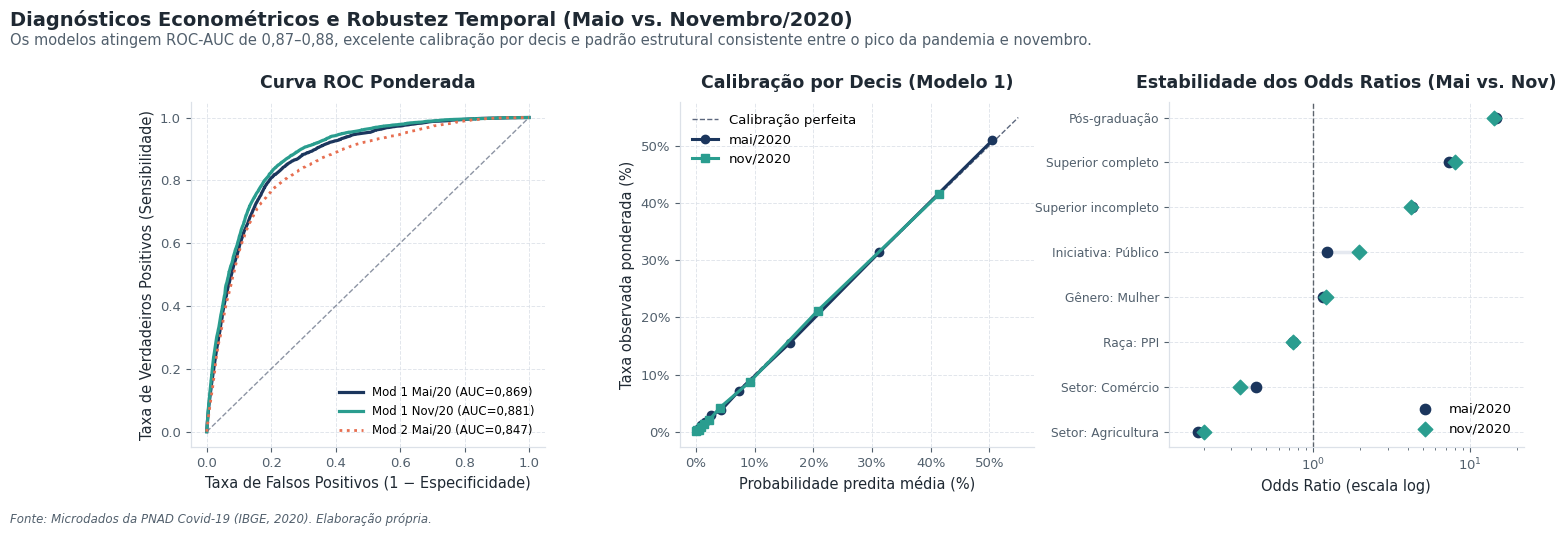

In [6]:
X1_nov, y1_nov, w1_nov = build_design_matrix_main(df_nov)
res1_nov = fit_weighted_logit(y1_nov, X1_nov, w1_nov)
summary1_nov = summarize_logit(res1_nov, X1_nov, w1_nov, include_ame=True)

X2_nov, y2_nov, w2_nov = build_design_matrix_interaction(df_nov)
res2_nov = fit_weighted_logit(y2_nov, X2_nov, w2_nov)

diag_df = pd.DataFrame(
    [
        {"modelo": "Modelo 1 (Efeitos Principais)", "mes": "mai/2020", **compute_diagnostics(res1_mai, y1_mai, X1_mai, w1_mai)},
        {"modelo": "Modelo 2 (Interações Superior)", "mes": "mai/2020", **compute_diagnostics(res2_mai, y2_mai, X2_mai, w2_mai)},
        {"modelo": "Modelo 1 (Efeitos Principais)", "mes": "nov/2020", **compute_diagnostics(res1_nov, y1_nov, X1_nov, w1_nov)},
        {"modelo": "Modelo 2 (Interações Superior)", "mes": "nov/2020", **compute_diagnostics(res2_nov, y2_nov, X2_nov, w2_nov)},
    ]
)
display(diag_df.round(4))

# Comparação de Odds Ratios e AMEs (Modelo 1: Maio vs Novembro)
comp_mai_nov = summary1_mai[["variavel", "label", "odds_ratio", "ame_pp"]].merge(
    summary1_nov[["variavel", "odds_ratio", "ame_pp"]],
    on="variavel",
    suffixes=("_mai", "_nov"),
)
print("\nComparação de Odds Ratios e AMEs — Modelo 1 (Mai vs. Nov/2020):")
display(comp_mai_nov[comp_mai_nov["variavel"] != "const"].round(3))

# Figura 09: Curva ROC, Calibração e Robustez Maio vs Novembro
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17.2, 5.4))
fig.subplots_adjust(top=0.79, bottom=0.15, wspace=0.38)

# Painel A: Curva ROC ponderada
p1_mai = res1_mai.predict(X1_mai)
p1_nov = res1_nov.predict(X1_nov)
p2_mai = res2_mai.predict(X2_mai)

fpr1m, tpr1m, auc1m = compute_weighted_roc(y1_mai, p1_mai, w1_mai)
fpr1n, tpr1n, auc1n = compute_weighted_roc(y1_nov, p1_nov, w1_nov)
fpr2m, tpr2m, auc2m = compute_weighted_roc(y2_mai, p2_mai, w2_mai)

ax1.plot([0, 1], [0, 1], ls="--", lw=1.0, color=PALETTE["slate"], alpha=0.7)
ax1.plot(fpr1m, tpr1m, lw=2.3, color=PALETTE["navy"], label=f"Mod 1 Mai/20 (AUC={format_ptbr_number(auc1m, 3)})")
ax1.plot(fpr1n, tpr1n, lw=2.3, color=PALETTE["teal"], label=f"Mod 1 Nov/20 (AUC={format_ptbr_number(auc1n, 3)})")
ax1.plot(fpr2m, tpr2m, lw=2.0, ls=":", color=PALETTE["coral"], label=f"Mod 2 Mai/20 (AUC={format_ptbr_number(auc2m, 3)})")
ax1.set_title("Curva ROC Ponderada", pad=10)
ax1.set_xlabel("Taxa de Falsos Positivos (1 − Especificidade)")
ax1.set_ylabel("Taxa de Verdadeiros Positivos (Sensibilidade)")
ax1.legend(loc="lower right", fontsize=8.5)

# Painel B: Calibração por decis (Modelo 1 Mai e Nov)
cal_mai = compute_calibration_bins(y1_mai, p1_mai, w1_mai, n_bins=10)
cal_nov = compute_calibration_bins(y1_nov, p1_nov, w1_nov, n_bins=10)
max_cal = max(cal_mai["taxa_observada_pct"].max(), cal_mai["prob_predita_pct"].max()) + 4
ax2.plot([0, max_cal], [0, max_cal], ls="--", lw=1.0, color=PALETTE["slate"], label="Calibração perfeita")
ax2.plot(cal_mai["prob_predita_pct"], cal_mai["taxa_observada_pct"], marker="o", lw=2.2, color=PALETTE["navy"], label="mai/2020")
ax2.plot(cal_nov["prob_predita_pct"], cal_nov["taxa_observada_pct"], marker="s", lw=2.2, color=PALETTE["teal"], label="nov/2020")
ax2.set_title("Calibração por Decis (Modelo 1)", pad=10)
ax2.set_xlabel("Probabilidade predita média (%)")
ax2.set_ylabel("Taxa observada ponderada (%)")
style_percent_axis(ax2, axis="x")
style_percent_axis(ax2, axis="y")
ax2.legend(loc="upper left")

# Painel C: Estabilidade temporal de ORs chave (Maio vs Novembro)
key_vars = [
    ("escolaridade__Pós-graduação, mestrado ou doutorado", "Pós-graduação"),
    ("escolaridade__Superior completo", "Superior completo"),
    ("escolaridade__Superior incompleto", "Superior incompleto"),
    ("iniciativa__Público", "Iniciativa: Público"),
    ("genero__Mulher", "Gênero: Mulher"),
    ("raca__Pretos, Pardos e Indígenas", "Raça: PPI"),
    ("setor__Comércio", "Setor: Comércio"),
    ("setor__Agricultura", "Setor: Agricultura"),
]
comp_sub = comp_mai_nov.set_index("variavel").loc[[k[0] for k in key_vars]].copy()
comp_sub["nome"] = [k[1] for k in key_vars]
comp_sub = comp_sub.iloc[::-1].reset_index(drop=True)

yk = np.arange(len(comp_sub))
ax3.axvline(1.0, color=PALETTE["dark_text"], lw=1.0, ls="--", alpha=0.7)
ax3.hlines(yk, comp_sub["odds_ratio_mai"], comp_sub["odds_ratio_nov"], color=PALETTE["light_gray"], lw=2.5)
ax3.scatter(comp_sub["odds_ratio_mai"], yk, color=PALETTE["navy"], s=55, zorder=3, label="mai/2020")
ax3.scatter(comp_sub["odds_ratio_nov"], yk, color=PALETTE["teal"], s=55, marker="D", zorder=4, label="nov/2020")
ax3.set_xscale("log")
ax3.set_yticks(yk)
ax3.set_yticklabels(comp_sub["nome"], fontsize=8.8)
ax3.set_xlim(0.12, 22)
ax3.set_title("Estabilidade dos Odds Ratios (Mai vs. Nov)", pad=10)
ax3.set_xlabel("Odds Ratio (escala log)")
ax3.legend(loc="lower right")

add_title_and_source(
    fig,
    "Diagnósticos Econométricos e Robustez Temporal (Maio vs. Novembro/2020)",
    "Os modelos atingem ROC-AUC de 0,87–0,88, excelente calibração por decis e padrão estrutural consistente entre o pico da pandemia e novembro.",
    title_y=0.96,
    subtitle_y=0.895,
    source_y=0.01,
)
save_figure(fig, "09_diagnosticos_e_robustez_mai_nov.png")
plt.show()


## 3.4 Síntese Executiva e Limitações Metodológicas

### Principais Achados
1. **O ensino superior é o eixo estruturante do trabalho remoto**: mesmo após controlar por setor, iniciativa, formalidade, idade, região, gênero e raça, possuir ensino superior completo aumenta a probabilidade média de trabalho remoto em **+21,7 p.p.** (OR = 7,34) e pós-graduação em **+35,5 p.p.** (OR = 14,65) frente ao ensino médio completo em maio/2020.
2. **Moderação da desigualdade racial e efeito setorial seletivo**: o termo de interação `Superior × Pretos, Pardos e Indígenas` (OR = 1,254, p = 0,0002) reduz a razão relativa de desvantagem entre trabalhadores negros e indígenas, e o diploma superior multiplica em **4,31 vezes** as chances relativas na Agricultura (elevando a probabilidade predita de 0,5% para 14,1%).
3. **Diferenciação público-privada ao longo de 2020**: com a retomada presencial do setor privado até novembro/2020, o *Odds Ratio* associado à iniciativa pública saltou de **1,22** (+1,9 p.p.) para **1,97** (+5,2 p.p.), evidenciando maior persistência institucional do teletrabalho no setor público.

### Limitações Metodológicas
- **Granularidade ocupacional**: a PNAD Covid-19 não disponibiliza os códigos de ocupação a 4 dígitos (COD), impedindo o pareamento direto com índices de viabilidade técnica por tarefa (como Dingel & Neiman, 2020) dentro do mesmo microdado.
- **Infraestrutura domiciliar**: a PNAD Covid-19 não coleta posse de computador e internet banda larga no domicílio, variáveis que explicam parte da restrição estrutural em regiões de menor renda.
- **Identificação correlacional**: trata-se de cortes transversais mensais ponderados; as relações estimadas capturam associações condicionais robustas, não efeitos causais experimentais.
